# Geral exercises

## Regressão Linear

### Exercício basilar

In [10]:
# Exercício resolvido

import numpy as np                  # Biblioteca de operações numericas
import matplotlib.pyplot as plt     # Biblioteca de Gráficos
x = np.arange(1, 9)
y = np.array([2.1, 3.9, 4.2, 6.1, 7.5, 8.3, 8.9, 10.4])

In [30]:
def reglin(x,y):
    '''
    Solução utilizando estrutura :  Sx ,Sy, Sxy, Sxx    
    Equivalentes ao comando polyfit : px=np.polyfit(x,y,1)  
    '''
    # Teste de dimensão entre vetores
    if (len(x)!=len(y)): 
        return print('Falha! X e Y tem dimensões diferentes!') 
    
    # Estrutura básica de regressão linear
    n=len(x)
    Sx ,Sy  = sum(x)   , sum(y)
    Sxy,Sxx = sum(x*y) , sum(x**2)
    a1=(n*Sxy-Sx*Sy)/(n*Sxx-Sx**2)
    a0=(Sxx*Sy-Sxy*Sx)/(n*Sxx-Sx**2)
    px=[float (a1),float (a0)] 
        
    return a1,a0

a1,a0 = np.round(reglin(x,y),4)
print(f"O polinômio p(x) para os vetores x e y é p(x) = {a1}*x + {a0}.")
    # 

O polinômio p(x) para os vetores x e y é p(x) = 1.1524*x + 1.2393.


Coef. angular: 1.1523809523809545
Coef. linear: 1.2392857142857079


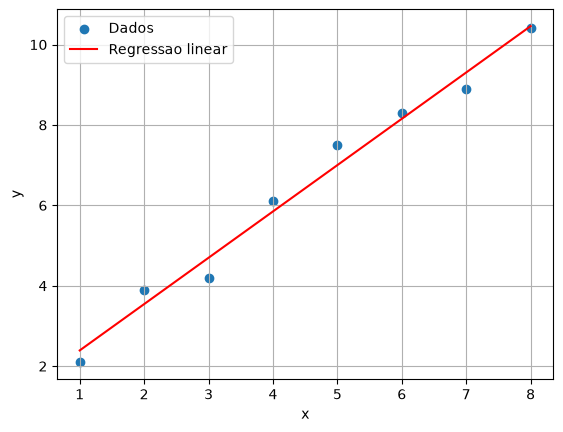

In [32]:
def graf_reglin(x,y):
    a1, a0 = reglin(x,y)             # Calcula a1 e a0
    print("Coef. angular:", a1)         # Exibe a inclinacao
    print("Coef. linear:", a0)          # Exibe o intercepto
    plt.scatter(x, y, label="Dados")    # Traça os pontos
    plt.plot(x, a0 + a1*x, 'r-',        # Desenha a reta
    label="Regressao linear")
    plt.xlabel("x")                     # Rotulo do eixo x
    plt.ylabel("y")                     # Rotulo do eixo y
    plt.legend()                        # Exibe a legenda
    plt.grid()                          # Adiciona a grade
    plt.show()                          # Mostra o grafico
graf_reglin(x,y)

In [57]:
### Solução com classe

class SolRegLin():
    def __init__(self,x,y,graf=0,arrend=4):
        self.x = x
        self.y = y
        self.arrend = arrend
        self.a1,self.a0 = np.round(self.reglin(),self.arrend)
        if graf==1: self.graf_reglin()
    
    def reglin(self):
        '''
        Solução utilizando estrutura :  Sx ,Sy, Sxy, Sxx    
        Equivalentes ao comando polyfit : px=np.polyfit(x,y,1)  
        '''
        x = self.x
        y = self.y
        # Teste de dimensão entre vetores
        if (len(x)!=len(y)): 
            return print('Falha! X e Y tem dimensões diferentes!') 
        
        # Estrutura básica de regressão linear
        n=len(x)
        Sx ,Sy  = sum(x)   , sum(y)
        Sxy,Sxx = sum(x*y) , sum(x**2)
        a1=np.round((n*Sxy-Sx*Sy)/(n*Sxx-Sx**2),self.arrend)
        a0=np.round((Sxx*Sy-Sxy*Sx)/(n*Sxx-Sx**2),self.arrend)
        print(f"O polinômio p(x) para os vetores x e y é p(x) = {a1}*x + {a0}.")
        return a1,a0

    def graf_reglin(self):
        print("Coef. angular:", self.a1)         # Exibe a inclinacao
        print("Coef. linear:", self.a0)          # Exibe o intercepto
        plt.scatter(self.x, self.y, label="Dados")    # Traça os pontos
        plt.plot(self.x, self.a0 + self.a1*x, 'r-',        # Desenha a reta
        label="Regressao linear")
        plt.xlabel("x")                     # Rotulo do eixo x
        plt.ylabel("y")                     # Rotulo do eixo y
        plt.legend()                        # Exibe a legenda
        plt.grid()                          # Adiciona a grade
        plt.show()  


# ----------------
x = np.arange(1, 9)
y = np.array([2.1, 3.9, 4.2, 6.1, 7.5, 8.3, 8.9, 10.4])
a = SolRegLin(x,y,graf=0,arrend=5)

O polinômio p(x) para os vetores x e y é p(x) = 1.15238*x + 1.23929.


# Extras

## Linear regression com gradiente descendente ( Aprendizado de Máquina )


In [5]:
## Linear regression com gradiente descendente
import numpy as np
# Dados de entrada e valores observados
X = np.arange(1, 9)
Y = np.array([2.1, 3.9, 4.2, 6.1, 7.5, 8.3, 8.9, 10.4])

# Inicialização dos parâmetros
w, b = 0.0, 0.0      # Coeficientes angulares
lr = 0.03            #  Taxa de aprendizagem

# Treinamento por gradiente descendente
for epoch in range(1000):
    # Calcula os valores previstos
    y_hat = w * X + b
    # Calcula os erros
    error = y_hat - Y
    # Calcula os gradientes
    dw = 2 * (error * X).mean()
    db = 2 * error.mean()
    # Atualiza os parâmetros
    w -= lr * dw
    b -= lr * db
    
# Exibe os parâmetros encontrados
print("Coeficiente angular (w):", w)
print("Intercepto (b):", b)
print("Equação ajustada: y =", w, "* x +", b) 

Coeficiente angular (w): 1.1523819953309542
Intercepto (b): 1.2392798505002396
Equação ajustada: y = 1.1523819953309542 * x + 1.2392798505002396


### Por que utilizar o gradiente descendente?


Existem duas abordagens comuns para ajustar uma regressão linear:

- Método analítico: calcula diretamente os parâmetros por meio das equações de mínimos quadrados.

- Gradiente descendente: ajusta iterativamente os parâmetros usando as derivadas da função de custo.

O gradiente descendente é especialmente importante em modelos de aprendizado de máquina nos quais a solução analítica é inviável ou computacionalmente dispendiosa.

Neste exemplo, a correção de b é fundamental: sem ela, o algoritmo não aprende o intercepto, e o modelo não representa adequadamente a regressão linear geral.

**Conclusão**: o código demonstra a estrutura básica do treinamento de um modelo linear. A previsão, o cálculo dos erros e os gradientes estão corretos; a atualização do intercepto precisa ser corrigida para que os dois parâmetros sejam aprendidos simultaneamente.

In [2]:
import numpy as np

def RegLin_ML(X:np.array([]),Y: np.array([]),lr = 0.03,ExibirParametros=1,Retorno_wb=1):
    w, b = 0.0, 0.0      # Coeficientes angulares
    lr = lr            # Taxa de aprendizagem
    # Treinamento por gradiente descendente
    for epoch in range(1000):
        y_hat = w * X + b                    # Calcula os valores previstos
        error = y_hat - Y                    # Calcula os erros
        dw = 2 * (error * X).mean()          # Calcula os gradientes
        db = 2 * error.mean()
        # Atualiza os parâmetros
        w -= lr * dw
        b -= lr * db
        
    if ExibirParametros == 1:    
        # Exibe os parâmetros encontrados
        print("Coeficiente angular (w):", w)
        print("Intercepto (b):", b)
        print("Equação ajustada: y =", w, "* x +", b) 
    if Retorno_wb == 1:
        return w,b    
#-------------
# Dados de entrada e valores observados

RegLin_ML(X,Y,lr,1,0)

Coeficiente angular (w): 1.1523819953309542
Intercepto (b): 1.2392798505002396
Equação ajustada: y = 1.1523819953309542 * x + 1.2392798505002396


In [3]:
# Ajustando para ciclos

hist_w, hist_b = [],[]
taxa_apr = [0.001,0.005,0.01,0.02,0.03] 

for lr in taxa_apr:
    w,b = RegLin_ML(X,Y,lr,0)
    hist_w.append(w)
    hist_b.append(b)

import pandas as pd
pd.options.display.float_format = '{:.6f}'.format

df = pd.DataFrame(
    {"Taxa": taxa_apr,
      "w" : hist_w,
      "b" : hist_b})
df

,Taxa,w,b
0,0.001000,1.271998,0.566760
1,0.005000,1.176559,1.103349
2,0.010000,1.155646,1.220928
3,0.020000,1.152440,1.238955
4,0.030000,1.152382,1.239280


### Percepção gŕafica

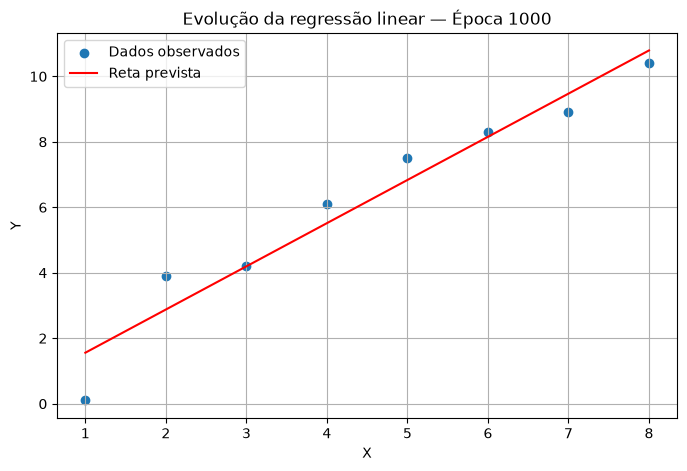

Coeficiente angular (w): 1.3190
Intercepto (b): 0.2393


In [14]:
X = np.arange(1, 9)
Y = np.array([0.1, 3.9, 4.2, 6.1, 7.5, 8.3, 8.9, 10.4])

RegLin_ML(X,Y,0.01,0,0)

import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import time

# Configuração do gráfico
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X, Y, label="Dados observados")

linha, = ax.plot(X, w * X + b, "r-", label="Reta prevista")  
# A vírgula desempacota a lista, atribuindo o único objeto diretamente à variável linha. Isso permite atualizar a reta durante o treinamento
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("Evolução da regressão linear")
ax.grid(True)
ax.legend()

for epoch in range(1000):
    # Calcula os valores previstos
    y_hat = w * X + b

    # Calcula os erros
    error = y_hat - Y

    # Calcula os gradientes
    dw = 2 * (error * X).mean()
    db = 2 * error.mean()

    # Atualiza os parâmetros
    w -= lr * dw
    b -= lr * db

    # Atualiza o gráfico a cada 10 épocas e na última época
    if epoch % 10 == 0 or epoch == 999:
        linha.set_ydata(w * X + b)
        ax.set_title(f"Evolução da regressão linear — Época {epoch + 1}")
        clear_output(wait=True)
        display(fig)
        time.sleep(0.01)

plt.close(fig)

print(f"Coeficiente angular (w): {w:.4f}")
print(f"Intercepto (b): {b:.4f}")
